# Credit Card Fraud Detection

Comparing Logistic Regression and Random Forest on a highly imbalanced fraud dataset.

In [1]:
import pandas as pd

In [4]:
df = pd.read_csv("creditcard.csv")

In [5]:
df

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


In [6]:
df['Class'].value_counts(normalize = True)

Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64

<Axes: xlabel='Class'>

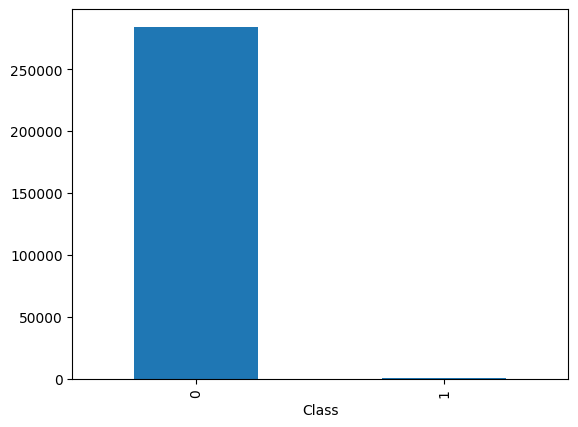

In [7]:
df["Class"].value_counts().plot(kind="bar")

In [8]:
df["Amount"].describe()

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

In [9]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [10]:
df.groupby('Class')['Amount'].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


In [11]:
from sklearn.model_selection import train_test_split

x = df.drop('Class', axis = 1)
y = df['Class']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42, stratify = y)

In [12]:
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

Class
0    0.998271
1    0.001729
Name: proportion, dtype: float64
Class
0    0.99828
1    0.00172
Name: proportion, dtype: float64


In [13]:
from sklearn.preprocessing import StandardScaler

x_train_raw = x_train.copy()
x_test_raw = x_test.copy()

scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [14]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state = 42)
x_train_smote, y_train_smote = smote.fit_resample(x_train, y_train)

print(y_train_smote.value_counts())
print(y_test.value_counts())

Class
0    227451
1    227451
Name: count, dtype: int64
Class
0    56864
1       98
Name: count, dtype: int64


In [15]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter = 1000, random_state = 42)
lr.fit(x_train_smote, y_train_smote)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [16]:
y_pred = lr.predict(x_test)

In [17]:
y_prob = lr.predict_proba(x_test)[:, 1]

In [18]:
from sklearn.metrics import precision_score, recall_score, roc_auc_score

print(precision_score(y_test, y_pred))
print(recall_score(y_test, y_pred))
print(roc_auc_score(y_test, y_prob))

0.057803468208092484
0.9183673469387755
0.9708434302252134


## Logistic Regression results

- Recall shows how many real fraud cases the model detects.
- Precision shows how often a transaction flagged as fraud is truly fraudulent.
- ROC-AUC measures how well the model ranks fraud above non-fraud across decision thresholds.


In [19]:
from sklearn.ensemble import RandomForestClassifier

In [20]:
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(x_train_smote, y_train_smote)

y_pred_rf = rf.predict(x_test)
y_prob_rf = rf.predict_proba(x_test)[:, 1]

In [21]:
print(precision_score(y_test, y_pred_rf))
print(recall_score(y_test, y_pred_rf))
print(roc_auc_score(y_test, y_prob_rf))

0.8709677419354839
0.826530612244898
0.9684484390970794


## Random Forest results

Random Forest has much higher precision than Logistic Regression, so its fraud alerts produce fewer false positives. Logistic Regression has higher recall, so it detects more real fraud cases. The preferred model depends on the cost of missed fraud versus false alarms.

In [22]:
from imblearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

param_grid = {'model__C': [0.01, 0.1, 1, 10]}

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])

grid = GridSearchCV(
    pipeline,
    param_grid,
    scoring='roc_auc',
    cv=3,
    n_jobs=-1
)

grid.fit(x_train_raw, y_train)

print(grid.best_params_)
print(grid.best_score_)

{'model__C': 0.01}
0.9819034707445199


In [23]:
y_pred_tuned = grid.predict(x_test_raw)
y_prob_tuned = grid.predict_proba(x_test_raw)[:, 1]

print(precision_score(y_test, y_pred_tuned))
print(recall_score(y_test, y_pred_tuned))
print(roc_auc_score(y_test, y_prob_tuned))

0.05851755526657997
0.9183673469387755
0.9714607283543693


In [26]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Logistic Regression (tuned)', 'Random Forest'],
    'Precision': [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_tuned),
        precision_score(y_test, y_pred_rf)
    ],
    'Recall': [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_tuned),
        recall_score(y_test, y_pred_rf)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, y_prob_tuned),
        roc_auc_score(y_test, y_prob_rf)
    ]
})

results.round(3)

,Model,Precision,Recall,ROC-AUC
0,Logistic Regression,0.058,0.918,0.971
1,Logistic Regression (tuned),0.059,0.918,0.971
2,Random Forest,0.871,0.827,0.968


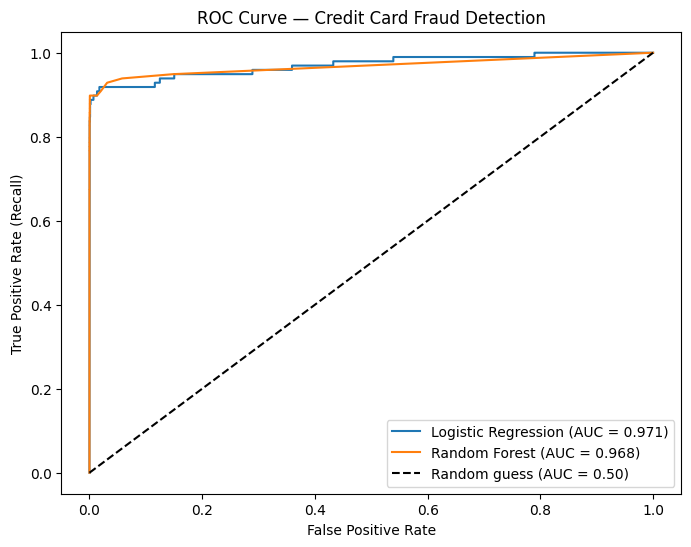

In [25]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(8, 6))
plt.plot(fpr_lr, tpr_lr, label='Logistic Regression (AUC = 0.971)')
plt.plot(fpr_rf, tpr_rf, label='Random Forest (AUC = 0.968)')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve — Credit Card Fraud Detection')
plt.legend()
plt.show()